# Manutenção Preditiva Industrial
### Análise de dados e classificação de falhas mecânicas

**Autor:** [Bruno Miguel Corrêa](https://github.com/CorreaBrunoMiguel)  
**Atividade:** Desenvolvimento de IA para Análise Preditiva [T3]  
**Etapa acadêmica:** Módulo 1 — Projeto Avaliativo  
**Tecnologias:** Python e Jupyter Notebook  

---

## Introdução

A identificação de falhas em equipamentos industriais pode apoiar o planejamento da manutenção e a redução de paradas não programadas. Nesse contexto, este projeto utiliza uma base histórica com medidas de temperatura, velocidade de rotação, torque, desgaste da ferramenta e categoria do equipamento para investigar a classificação de seu estado operacional.

O objetivo é desenvolver e comparar dois classificadores — K-Nearest Neighbors (KNN) e Árvore de Decisão — considerando a variável alvo `falha_maquina`, em que **0 representa funcionamento normal** e **1 representa ocorrência de falha**.

O trabalho está organizado em sete fases: análise exploratória, limpeza e tratamento dos dados, engenharia de atributos, divisão e balanceamento, escalonamento, ajuste de hiperparâmetros e avaliação final. As escolhas técnicas estão documentadas junto às evidências obtidas, permitindo acompanhar o raciocínio da análise e verificar os resultados.

A comparação exigida pelo projeto utiliza a acurácia nos conjuntos de treino e teste, com discussão dos indícios de sobreajuste e das limitações do experimento.

## Fontes do projeto

- **Base de dados:** [manutencao_preditiva.csv](../data/manutencao_preditiva.csv).
- **Enunciado oficial:** [requisitos e critérios de avaliação](../docs/enunciado-projeto.md).
- **Anotações do Departamento de Engenharia:** [descrição das colunas e restrições de uso na modelagem](../docs/referencias/anotacoes-engenharia.docx).

## Preparação do ambiente

In [1]:
import sys
import sklearn
import imblearn

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

from math import pi

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import confusion_matrix, precision_score, recall_score
from imblearn.under_sampling import RandomUnderSampler

print("Python      :", sys.version.split()[0])
print("Pandas      :", pd.__version__)
print("Seaborn     :", sns.__version__)
print("Numpy       :", np.__version__)
print("Scikit-Learn:", sklearn.__version__)
print("Imbalanced  :", imblearn.__version__)

# Configurações visual
sns.set_theme(style="whitegrid")

Python      : 3.13.14
Pandas      : 3.0.5
Seaborn     : 0.13.2
Numpy       : 2.5.1
Scikit-Learn: 1.9.0
Imbalanced  : 0.14.2


## Fase 1 — Análise exploratória dos dados (EDA)

### Inspeção inicial da base

A inspeção inicial busca conhecer a estrutura dos dados e identificar características relevantes para a modelagem. Para isso, são examinadas uma amostra dos registros, as dimensões da base, os tipos das colunas e as estatísticas descritivas. Também são investigados o padrão inicial de ausências e a distribuição dos tipos de produto e da variável alvo.

Os resultados desta seção descrevem a base original, anterior aos procedimentos de limpeza e transformação.

In [2]:
df_origin = pd.read_csv("../data/manutencao_preditiva.csv", index_col="udi")
df = df_origin.copy()

df.head()

,id_produto,tipo,temperatura_ar_k,temperatura_processo_k,velocidade_rotacao_rpm,torque_nm,desgaste_ferramenta_min,falha_maquina,falha_twf,falha_hdf,falha_pwf,falha_osf,falha_rnf
udi,,,,,,,,,,,,,
1,M14860,M,298.1,308.6,1551.0,42.8,0,0,0,0,0,0,0
2,L47181,L,298.2,308.7,1408.0,46.3,3,0,0,0,0,0,0
3,L47182,L,298.1,308.5,1498.0,49.4,5,0,0,0,0,0,0
4,L47183,L,NaN,NaN,NaN,NaN,7,0,0,0,0,0,0
5,L47184,L,298.2,308.7,1408.0,40.0,9,0,0,0,0,0,0


### Papel das colunas

Conforme as anotações do Departamento de Engenharia, as colunas possuem funções distintas na análise:

| Grupo | Colunas | Função |
| --- | --- | --- |
| Identificadores | `udi`, `id_produto` | Identificação dos registros e produtos. |
| Categoria do produto | `tipo` | Classificação do produto nas categorias L, M e H. |
| Medidas operacionais | Temperaturas, velocidade de rotação, torque e desgaste da ferramenta | Caracterização das condições operacionais; candidatas a variáveis preditoras. |
| Variável alvo | `falha_maquina` | Funcionamento normal (0) ou ocorrência de falha (1). |
| Indicadores históricos de falha | `falha_twf`, `falha_hdf`, `falha_pwf`, `falha_osf`, `falha_rnf` | Informações históricas com uso restrito pela engenharia. |

As temperaturas estão expressas em kelvin, a rotação em rpm, o torque em N·m e o desgaste da ferramenta em minutos. Os identificadores representam códigos, mesmo quando armazenados como números.

Por determinação da engenharia, os cinco indicadores históricos de falha serão excluídos das entradas dos modelos e não serão utilizados na construção de atributos derivados.

In [3]:
linhas, colunas = df.shape

print(
    f"""
Dataset possui:
    - Linhas: {linhas}
    - Colunas: {colunas}
"""
)

print("========== \n")

display(df.dtypes)


Dataset possui:
    - Linhas: 10000
    - Colunas: 13




id_produto                     str
tipo                           str
temperatura_ar_k           float64
temperatura_processo_k     float64
velocidade_rotacao_rpm     float64
torque_nm                  float64
desgaste_ferramenta_min      int64
falha_maquina                int64
falha_twf                    int64
falha_hdf                    int64
falha_pwf                    int64
falha_osf                    int64
falha_rnf                    int64
dtype: object

A base original contém 10.000 registros e 14 campos. Na leitura, o identificador `udi` foi definido como índice do DataFrame. Por isso, `df.shape` apresenta 10.000 linhas e 13 colunas, mantendo `udi` como índice.

In [4]:
display(df.describe())

,temperatura_ar_k,temperatura_processo_k,velocidade_rotacao_rpm,torque_nm,desgaste_ferramenta_min,falha_maquina,falha_twf,falha_hdf,falha_pwf,falha_osf,falha_rnf
count,9500.000000,9500.000000,9500.000000,9500.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.00000
mean,300.002158,310.000895,1539.245263,39.974168,107.951000,0.033900,0.004600,0.011500,0.009500,0.009800,0.00190
std,2.001689,1.486432,180.273589,9.995453,63.654147,0.180981,0.067671,0.106625,0.097009,0.098514,0.04355
min,295.300000,305.700000,1168.000000,3.800000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000
25%,298.300000,308.800000,1423.000000,33.100000,53.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000
50%,300.100000,310.100000,1504.000000,40.100000,108.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000
75%,301.500000,311.100000,1613.000000,46.700000,162.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.00000
max,304.500000,313.800000,2886.000000,76.600000,253.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.00000


In [5]:
col_dados_faltantes = [
    "temperatura_ar_k",
    "temperatura_processo_k",
    "velocidade_rotacao_rpm",
    "torque_nm",
]

ausencias_por_registro = df[col_dados_faltantes].isna().sum(axis=1)

resumo_ausencias = (
    ausencias_por_registro.value_counts()
    .sort_index()
    .rename_axis("Medidas ausentes por registro")
    .reset_index(name="Quantidade de registros")
)

resumo_ausencias["Percentual da base"] = resumo_ausencias[
    "Quantidade de registros"
] / len(df)

display(
    resumo_ausencias.style.hide(axis="index")
    .format(
        {
            "Quantidade de registros": "{:,.0f}",
            "Percentual da base": "{:.2%}",
        },
        decimal=",",
        thousands=".",
    )
    .set_caption("Ausências nas quatro medidas operacionais")
)

Medidas ausentes por registro,Quantidade de registros,Percentual da base
0,9.500,"95,00%"
4,500,"5,00%"


### Padrão inicial de valores ausentes

O resumo estatístico revelou 500 valores ausentes em cada uma das quatro medidas: temperatura do ar, temperatura do processo, velocidade de rotação e torque.

A verificação por linha confirmou que essas ausências coincidem nos mesmos 500 registros, equivalentes a 5% da base. Nos outros 9.500 registros, as quatro medidas estão presentes. Assim, o padrão observado é de ausência conjunta dessas medidas.

A variável alvo está preenchida nos 10.000 registros. O tratamento das ausências e sua justificativa serão apresentados na Fase 2 — Limpeza e tratamento dos dados.

In [6]:
total = len(df)
sem_falhas = (df["falha_maquina"] == 0).sum()
com_falhas = (df["falha_maquina"] == 1).sum()

resumo = pd.DataFrame(
    {
        "Total de registros": [total],
        "Sem falhas": [sem_falhas],
        "% Sem falhas": [sem_falhas / total],
        "Com falhas": [com_falhas],
        "% Com falhas": [com_falhas / total],
    }
)

display(
    resumo.style.hide(axis="index").format(
        {
            "Total de registros": "{:,}",
            "Sem falhas": "{:,}",
            "% Sem falhas": "{:.2%}",
            "Com falhas": "{:,}",
            "% Com falhas": "{:.2%}",
        }
    )
)

print("\n========== \n")

tipos = pd.DataFrame(
    {
        "Quantidade": df["tipo"].value_counts(dropna=False),
        "Percentual_Base": df["tipo"].value_counts(normalize=True, dropna=False),
    }
).reset_index()
tipos["qtd_falhas"] = tipos["tipo"].map(df.groupby("tipo")["falha_maquina"].sum())
tipos["falhas_%"] = tipos.qtd_falhas / tipos.Quantidade
display(
    tipos.style.hide(axis="index").format(
        {"Percentual_Base": "{:.2%}", "falhas_%": "{:.2%}"}
    )
)

Total de registros,Sem falhas,% Sem falhas,Com falhas,% Com falhas
"10,000","9,661",96.61%,339,3.39%


tipo,Quantidade,Percentual_Base,qtd_falhas,falhas_%
L,6000,60.00%,235,3.92%
M,2997,29.97%,83,2.77%
H,1003,10.03%,21,2.09%


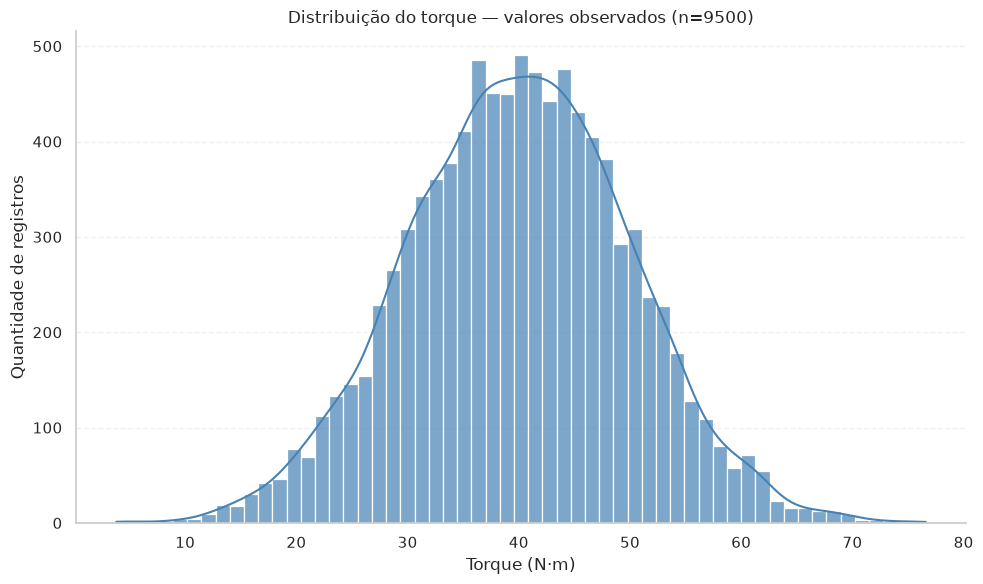

In [7]:
valores_observados = df["torque_nm"].notna().sum()

fig, ax = plt.subplots(figsize=(10, 6))

sns.histplot(
    data=df,
    x="torque_nm",
    bins="auto",
    kde=True,
    color="steelblue",
    edgecolor="white",
    alpha=0.7,
    ax=ax,
)

ax.set_title(f"Distribuição do torque — valores observados (n={valores_observados})")
ax.set_xlabel("Torque (N·m)")
ax.set_ylabel("Quantidade de registros")

ax.grid(axis="y", linestyle="--", alpha=0.3)
ax.grid(axis="x", visible=False)
sns.despine(ax=ax)

plt.tight_layout()
plt.show()

### Análise da distribuição do torque

Os valores de torque se concentram perto de 40 N·m, com uma distribuição unimodal e aproximadamente simétrica. A média de 39,97 N·m ficou próxima da mediana de 40,10 N·m, e o desvio padrão foi de cerca de 10 N·m.

O gráfico considera os 9.500 valores disponíveis; as 500 ausências não entram nessa distribuição. Esse formato ajudou na escolha da média para preencher o torque, junto com a análise dos extremos na Fase 2. Calculei o valor de preenchimento apenas no treino e usei o mesmo valor no teste.

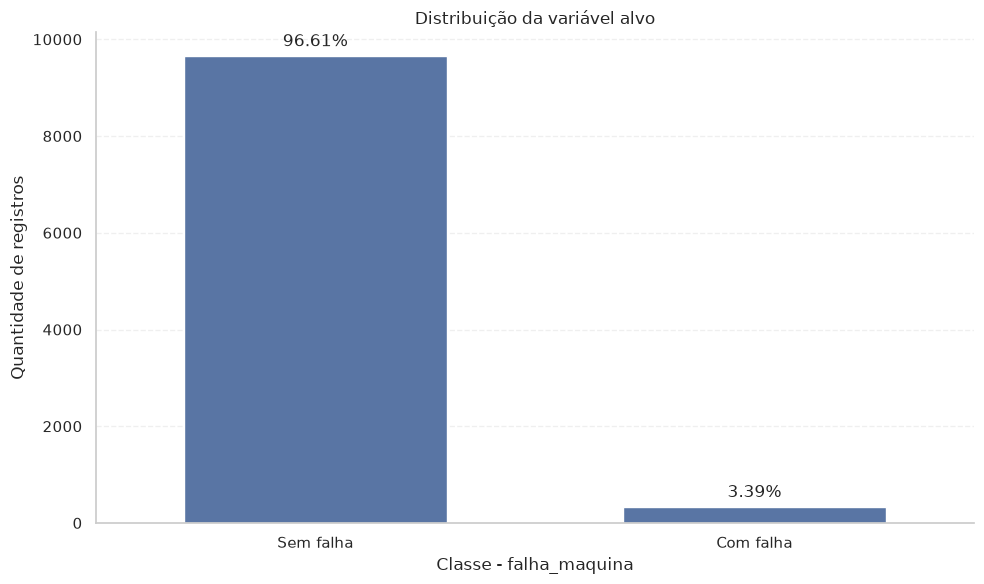

In [8]:
fig, ax = plt.subplots(figsize=(10, 6))

total = len(df)

sns.countplot(
    data=df,
    x="falha_maquina",
    order=[0, 1],
    width=0.6,
    edgecolor="white",
    lw=1,
    stat="count",
    ax=ax,
)

ax.set_title("Distribuição da variável alvo")
ax.set_xlabel("Classe - falha_maquina", fontsize=12)
ax.set_ylabel("Quantidade de registros")

# Rótulos acima das barras
for container in ax.containers:
    ax.bar_label(
        container,
        labels=[f"{barra.get_height() / total:.2%}" for barra in container],
        padding=4,
    )

# Rótulos
ax.set_xticks([0, 1])
ax.set_xticklabels(["Sem falha", "Com falha"])

ax.set_ylim(bottom=0)
ax.grid(axis="y", linestyle="--", alpha=0.3)
ax.grid(axis="x", visible=False)
sns.despine(ax=ax)

plt.tight_layout()
plt.show()

### Análise do desbalanceamento da variável alvo

A variável `falha_maquina` apresenta forte desbalanceamento: 96,61% dos registros correspondem ao funcionamento normal e 3,39% à ocorrência de falha.

Essa predominância exige cuidado na interpretação da acurácia. Um classificador que previsse funcionamento normal para todos os registros alcançaria 96,61% de acurácia no conjunto completo, sem detectar nenhuma falha. Portanto, uma taxa elevada de acertos, isoladamente, não demonstra capacidade de identificar a classe minoritária.

Esse resultado fundamenta a divisão estratificada entre treino e teste e a aplicação de reamostragem exclusivamente no conjunto de treino. O teste deve preservar a proporção original das classes para representar o cenário observado na base.

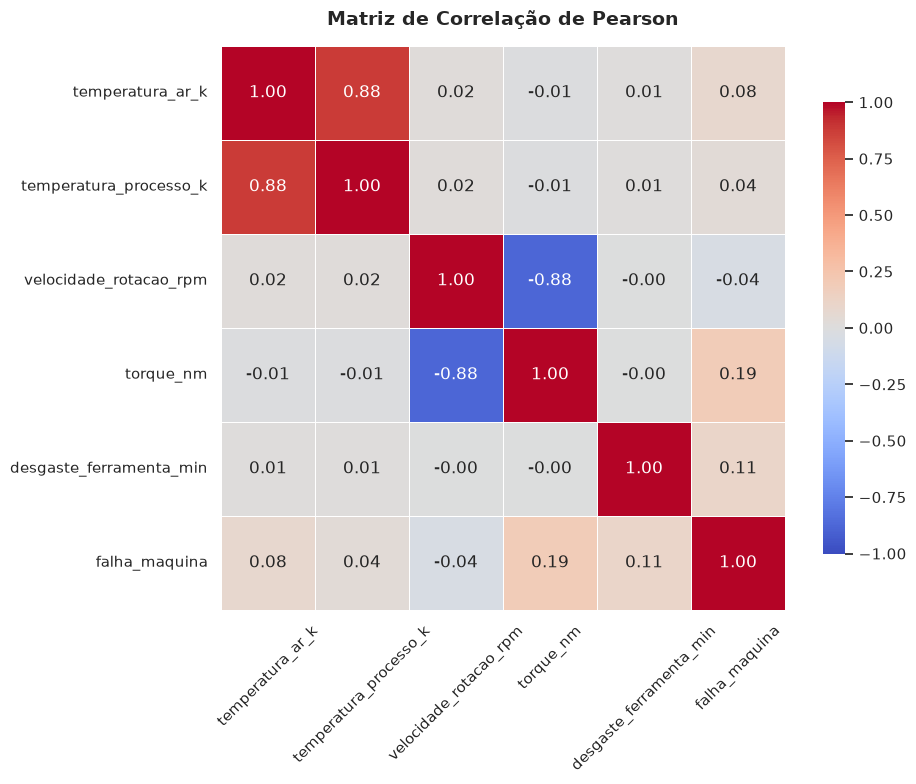

In [9]:
colunas = "temperatura_ar_k temperatura_processo_k velocidade_rotacao_rpm torque_nm desgaste_ferramenta_min falha_maquina".split()

matriz_corr = df[colunas].corr(method="pearson")

fig, ax = plt.subplots(figsize=(10, 8))

sns.heatmap(
    data=matriz_corr,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    vmin=-1,
    vmax=1,
    center=0,
    square=True,
    lw=0.5,
    cbar_kws={"shrink": 0.8},
    ax=ax,
)

ax.set_title("Matriz de Correlação de Pearson", fontsize=14, fontweight="bold", pad=15)

ax.tick_params(axis="x", rotation=45)
ax.tick_params(axis="y", rotation=0)

plt.tight_layout()
plt.show()

### Análise das correlações

A matriz de Pearson apresenta forte associação linear positiva entre temperatura do ar e temperatura do processo, com coeficiente de aproximadamente 0,88. Também apresenta forte associação linear negativa entre velocidade de rotação e torque, com coeficiente de aproximadamente −0,88: maiores valores de uma variável tendem a acompanhar menores valores da outra. Essas associações não demonstram causalidade.

Entre as medidas operacionais analisadas, o torque apresenta a maior correlação em magnitude com `falha_maquina`, aproximadamente 0,19, seguido pelo desgaste da ferramenta, aproximadamente 0,11. Ambos os valores indicam associações lineares fracas.

As correlações com o alvo são fracas, mas isso não é motivo suficiente para excluir essas variáveis. Pearson mede relações lineares e não mostra, sozinho, como os atributos atuam em conjunto. Por isso, mantive as cinco medidas operacionais na modelagem.

## Fase 2 — Limpeza e tratamento dos dados

In [10]:
registros_antes = len(df)

udi_unico = df.index.nunique()
id_produto_unico = df.id_produto.nunique()
duplicados = df.duplicated().sum()

df = df.drop_duplicates()

registros_removidos = registros_antes - len(df)

print(f"Índice udi com valores únicos: {udi_unico == registros_antes}")
print(
    f"Coluna id_produto com valores únicos: " f"{id_produto_unico == registros_antes}"
)
print(f"Registros duplicados identificados: {duplicados}")
print(f"Registros removidos: {registros_removidos}")
print(f"Registros após o tratamento: {len(df)}")

Índice udi com valores únicos: True
Coluna id_produto com valores únicos: True
Registros duplicados identificados: 0
Registros removidos: 0
Registros após o tratamento: 10000


In [11]:
tabela_ausentes = pd.DataFrame(
    {
        "coluna": df.columns,
        "valores ausentes": df.isna().sum().values,
        "porcentagem de ausentes": (df.isna().mean().values),
    }
)

display(
    tabela_ausentes.style.hide(axis="index").format(
        {"porcentagem de ausentes": "{:.1%}"}
    )
)

coluna,valores ausentes,porcentagem de ausentes
id_produto,0,0.0%
tipo,0,0.0%
temperatura_ar_k,500,5.0%
temperatura_processo_k,500,5.0%
velocidade_rotacao_rpm,500,5.0%
torque_nm,500,5.0%
desgaste_ferramenta_min,0,0.0%
falha_maquina,0,0.0%
falha_twf,0,0.0%
falha_hdf,0,0.0%


In [12]:
print("tipo :", *df["tipo"].unique().tolist())
print("falha_maquina:", *sorted(df["falha_maquina"].unique().tolist()))

tipo : M L H
falha_maquina: 0 1


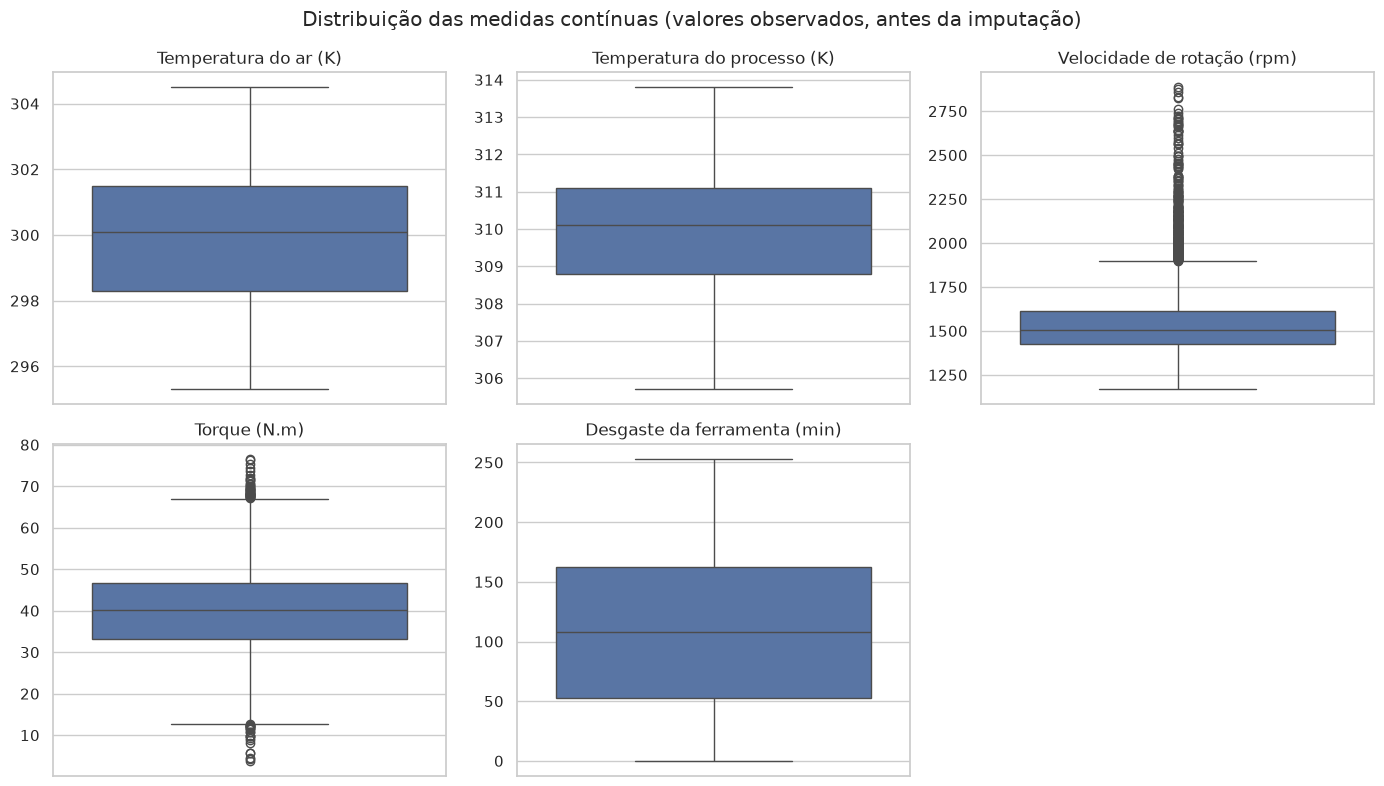

In [13]:
medidas = {
    "temperatura_ar_k": "Temperatura do ar (K)",
    "temperatura_processo_k": "Temperatura do processo (K)",
    "velocidade_rotacao_rpm": "Velocidade de rotação (rpm)",
    "torque_nm": "Torque (N.m)",
    "desgaste_ferramenta_min": "Desgaste da ferramenta (min)",
}

fig, axes = plt.subplots(2, 3, figsize=(14, 8))
axes = axes.ravel()

for ax, (col, rotulo) in zip(axes, medidas.items()):
    sns.boxplot(data=df, y=col, ax=ax)
    ax.set_title(rotulo)
    ax.set_ylabel("")
    ax.set_xlabel("")

axes[5].set_visible(False)

fig.suptitle(
    "Distribuição das medidas contínuas (valores observados, antes da imputação)"
)
plt.tight_layout()
plt.show()

### Diagnóstico de integridade e valores extremos

Não foram encontrados registros duplicados considerando todas as colunas do DataFrame. Os identificadores `udi` e `id_produto` são únicos; portanto, nenhuma linha foi removida. As categorias observadas são L, M e H, e o alvo contém apenas 0 e 1. As ausências estão restritas às quatro medidas identificadas na EDA; categoria, alvo e desgaste estão completos.

Os boxplots mostram valores extremos superiores na rotação e extremos nos dois lados da distribuição do torque. As temperaturas e o desgaste não apresentam pontos fora dos bigodes pelo critério utilizado.

Os extremos foram preservados: sua identificação estatística não comprova erro de medição. Excluí-los automaticamente poderia eliminar condições operacionais relevantes. Esta análise não demonstra causalidade entre esses valores e as falhas.

### Separação dos dados antes da imputação

As entradas dos modelos incluem a categoria do produto e as cinco medidas operacionais; `falha_maquina` é o alvo.

A divisão estratificada em 80% de treino e 20% de teste, com `random_state=1986`, foi antecipada para que os valores de imputação sejam calculados exclusivamente no treino. Essa mesma divisão será utilizada na Fase 4, sem novo sorteio. As verificações confirmam alinhamento entre X e y e ausência de índices compartilhados entre treino e teste.

In [14]:
colunas_preditoras = [
    "tipo",
    "temperatura_ar_k",
    "temperatura_processo_k",
    "velocidade_rotacao_rpm",
    "torque_nm",
    "desgaste_ferramenta_min",
]

X = df[colunas_preditoras]
y = df["falha_maquina"]

print(f"Dimensões de X: {X.shape}")
print(f"Dimensões de y: {y.shape}")
print(f"Índices de X e y alinhados: {X.index.equals(y.index)}")

Dimensões de X: (10000, 6)
Dimensões de y: (10000,)
Índices de X e y alinhados: True


In [15]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=1986, stratify=y
)

resumo_divisao = pd.DataFrame(
    {
        "Conjunto": ["Treino", "Teste"],
        "Registros": [len(X_train), len(X_test)],
        "Taxa de falha": [y_train.mean(), y_test.mean()],
        "X e y alinhados": [
            X_train.index.equals(y_train.index),
            X_test.index.equals(y_test.index),
        ],
    }
)

display(
    resumo_divisao.style.hide(axis="index")
    .format(
        {
            "Registros": "{:,.0f}",
            "Taxa de falha": "{:.2%}",
        },
        decimal=",",
        thousands=".",
    )
    .set_caption("Divisão estratificada — antes da reamostragem")
)

print(
    "Índices compartilhados entre treino e teste:",
    len(X_train.index.intersection(X_test.index)),
)

Conjunto,Registros,Taxa de falha,X e y alinhados
Treino,8.000,"3,39%",True
Teste,2.000,"3,40%",True


Índices compartilhados entre treino e teste: 0


In [16]:
cols = [
    "temperatura_ar_k",
    "temperatura_processo_k",
    "velocidade_rotacao_rpm",
    "torque_nm",
]

estatisticas_treino_tipo = X_train.groupby("tipo")[cols].agg(["mean", "median", "std"])

rotulos = {
    "temperatura_ar_k": "Temp. ar (K)",
    "temperatura_processo_k": "Temp. processo (K)",
    "velocidade_rotacao_rpm": "Rotação (rpm)",
    "torque_nm": "Torque (N·m)",
}

display(
    estatisticas_treino_tipo.loc[["L", "M", "H"]]
    .rename(columns=rotulos, level=0)
    .rename(
        columns={
            "mean": "Média",
            "median": "Mediana",
            "std": "Desvio padrão",
        },
        level=1,
    )
    .T.rename_axis(index=["Medida", "Estatística"], columns="Tipo")
    .style.format(precision=2, decimal=",", thousands=".")
    .set_caption("Comparação das medidas por tipo — conjunto de treino")
)

### Estratégia de imputação

A comparação no treino mostrou diferenças pequenas entre os tipos em relação à dispersão das medidas. Adotou-se, portanto, um valor de preenchimento por coluna, sem agrupamento por tipo.

| Coluna | Medida escolhida | Justificativa |
|---|---|---|
| `temperatura_ar_k` | Média | Média e mediana próximas, sem extremos identificados no boxplot. |
| `temperatura_processo_k` | Média | Média e mediana próximas, sem extremos identificados no boxplot. |
| `velocidade_rotacao_rpm` | Mediana | Assimetria à direita e valores elevados; a mediana é menos sensível à magnitude desses extremos. |
| `torque_nm` | Média | Distribuição aproximadamente simétrica e proximidade entre média e mediana, apesar dos extremos observados. |

Os valores foram calculados apenas no treino e reutilizados no teste. A verificação após o preenchimento confirma ausência de nulos nas preditoras dos dois conjuntos. A imputação fornece valores substitutos e não recupera as medições originais.

In [17]:
base_imputacao = {
    "temperatura_ar_k": X_train.temperatura_ar_k.mean(),
    "temperatura_processo_k": X_train.temperatura_processo_k.mean(),
    "velocidade_rotacao_rpm": X_train.velocidade_rotacao_rpm.median(),
    "torque_nm": X_train.torque_nm.mean(),
}

X_train = X_train.fillna(base_imputacao)
X_test = X_test.fillna(base_imputacao)

valores_imputacao = pd.DataFrame(
    {
        "Coluna": list(base_imputacao.keys()),
        "Valor de preenchimento": list(base_imputacao.values()),
    }
)

display(
    valores_imputacao.style.hide(axis="index")
    .format(precision=2, decimal=",", thousands=".")
    .set_caption("Valores de imputação calculados no treino")
)

print(f"Valores ausentes em X_train: {X_train.isna().sum().sum()}")
print(f"Valores ausentes em X_test: {X_test.isna().sum().sum()}")

Coluna,Valor de preenchimento
temperatura_ar_k,"299,99"
temperatura_processo_k,"310,00"
velocidade_rotacao_rpm,"1.502,00"
torque_nm,"40,01"


Valores ausentes em X_train: 0
Valores ausentes em X_test: 0


## Fase 3 — Engenharia de atributos

### Potência mecânica de rotação

Foi criada a variável `potencia_mecanica_w`, combinando torque e velocidade de rotação para estimar a potência mecânica. A rotação foi convertida de rpm para rad/s pelo fator $(2\pi/60)$; sua multiplicação pelo torque em N·m resulta em watts.

Esse atributo explicita a interação multiplicativa entre duas medidas operacionais, oferecendo aos modelos uma representação com significado físico que pode apoiar a identificação de padrões, sem garantir melhoria preditiva.

A mesma transformação foi aplicada ao treino e ao teste após a imputação. A potência é uma variável derivada, e não uma nova medição independente.

In [18]:
X_train["potencia_mecanica_w"] = (
    X_train.torque_nm * X_train.velocidade_rotacao_rpm * (2 * pi) / 60
)
X_test["potencia_mecanica_w"] = (
    X_test.torque_nm * X_test.velocidade_rotacao_rpm * (2 * pi) / 60
)

cols_check = ["torque_nm", "velocidade_rotacao_rpm", "potencia_mecanica_w"]

amostra = pd.concat(
    {"Treino": X_train[cols_check].head(3), "Teste": X_test[cols_check].head(3)},
    names=["Base", None],
)
display(amostra.style.format(precision=2, decimal=",", thousands="."))

In [19]:
coluna_potencia_train = X_train.potencia_mecanica_w
coluna_potencia_test = X_test.potencia_mecanica_w

resumo_potencia = pd.DataFrame(
    {
        "Conjunto": ["Treino", "Teste"],
        "Valores ausentes": [
            coluna_potencia_train.isna().sum(),
            coluna_potencia_test.isna().sum(),
        ],
        "Todos finitos": [
            np.isfinite(coluna_potencia_train).all(),
            np.isfinite(coluna_potencia_test).all(),
        ],
        "Mínimo (W)": [
            coluna_potencia_train.min(),
            coluna_potencia_test.min(),
        ],
        "Máximo (W)": [
            coluna_potencia_train.max(),
            coluna_potencia_test.max(),
        ],
    }
)

display(
    resumo_potencia.style.hide(axis="index")
    .format(
        {
            "Mínimo (W)": "{:,.2f}",
            "Máximo (W)": "{:,.2f}",
        },
        decimal=",",
        thousands=".",
    )
    .set_caption("Verificação da potência mecânica")
)

Conjunto,Valores ausentes,Todos finitos,Mínimo (W),Máximo (W)
Treino,0,True,"1.148,44","10.469,92"
Teste,0,True,"2.649,96","10.233,15"


## Fase 4 — Divisão e balanceamento dos dados

### Divisão e representação das categorias

Esta fase reutiliza a divisão estratificada 80/20 realizada na Fase 2. A estratificação preserva aproximadamente a proporção das classes nos dois conjuntos, e ambos os modelos utilizarão os mesmos registros de teste.

A variável `tipo` foi representada por três colunas dummy, correspondentes a L, M e H. Essa representação evita impor distâncias decorrentes de códigos numéricos arbitrários. As três colunas foram mantidas para que as diferenças entre categorias contribuam igualmente para a distância do KNN.

In [20]:
cat_tipo = pd.CategoricalDtype(["L", "M", "H"])

X_train = pd.get_dummies(
    X_train.assign(tipo=X_train["tipo"].astype(cat_tipo)),
    columns=["tipo"],
    dtype=int,
)
X_test = pd.get_dummies(
    X_test.assign(tipo=X_test["tipo"].astype(cat_tipo)),
    columns=["tipo"],
    dtype=int,
)

print(
    "Treino e teste possuem as mesmas colunas, na mesma ordem:",
    X_train.columns.equals(X_test.columns),
)

Treino e teste possuem as mesmas colunas, na mesma ordem: True


### Reamostragem do treino

Foi aplicado Random Under Sampling exclusivamente ao treino, sem reposição e com `random_state=1986`. A razão entre falhas e registros normais foi definida como 0,25, resultando em uma falha para quatro registros normais.

Escolhi a redução parcial para manter mais registros normais do que na proporção 1:1. Mesmo assim, 6.645 registros normais ficaram fora do treino reamostrado, o equivalente a 83,06% do treino original. Esse descarte pode reduzir a diversidade das condições operacionais representadas e não garante melhora no desempenho.

O teste preserva seus registros e sua distribuição de classes.

In [21]:
rus = RandomUnderSampler(
    sampling_strategy=0.25,
    random_state=1986,
    replacement=False,
)

X_train_resampled, y_train_resampled = rus.fit_resample(X_train, y_train)

contagens = pd.DataFrame(
    {
        "Treino original": y_train.value_counts(),
        "Treino reamostrado": y_train_resampled.value_counts(),
        "Teste preservado": y_test.value_counts(),
    }
).T.rename(columns={0: "Sem falha", 1: "Com falha"})

contagens["Total"] = contagens.sum(axis=1)
contagens["Taxa de falha"] = contagens["Com falha"] / contagens["Total"]

display(
    contagens.rename_axis("Conjunto")
    .style.format(
        {
            "Sem falha": "{:,.0f}",
            "Com falha": "{:,.0f}",
            "Total": "{:,.0f}",
            "Taxa de falha": "{:.2%}",
        },
        decimal=",",
        thousands=".",
    )
    .set_caption("Distribuição das classes antes e depois da reamostragem")
)

registros_descartados = len(X_train) - len(X_train_resampled)

print(f"Registros retirados do treino: {registros_descartados}")
print(f"Dimensões do treino reamostrado: {X_train_resampled.shape}")
print(
    "X e y reamostrados alinhados:",
    X_train_resampled.index.equals(y_train_resampled.index),
)

falha_maquina,Sem falha,Com falha,Total,Taxa de falha
Conjunto,,,,
Treino original,7.729,271,8.000,"3,39%"
Treino reamostrado,1.084,271,1.355,"20,00%"
Teste preservado,1.932,68,2.000,"3,40%"


Registros retirados do treino: 6645
Dimensões do treino reamostrado: (1355, 9)
X e y reamostrados alinhados: True


## Fase 5 — Escalonamento de variáveis

### Escalonamento das entradas do KNN

O KNN utiliza distâncias entre registros; diferenças de escala entre as variáveis podem influenciar excessivamente esse cálculo. Por isso, as seis medidas contínuas foram padronizadas com StandardScaler.

O scaler foi ajustado somente no treino reamostrado, utilizando `fit_transform`. O teste recebeu `transform` com os mesmos parâmetros. As três dummies permaneceram em 0/1.

A árvore utilizará os dados sem escalonamento, pois seus cortes avaliam uma variável por vez. A padronização preserva a ordem dos valores e permite cortes equivalentes, sem a necessidade de uniformizar as escalas.

In [22]:
colunas_continuas = [
    "temperatura_ar_k",
    "temperatura_processo_k",
    "velocidade_rotacao_rpm",
    "torque_nm",
    "desgaste_ferramenta_min",
    "potencia_mecanica_w",
]

X_train_knn = X_train_resampled.copy()
X_test_knn = X_test.copy()

scaler = StandardScaler()

X_train_knn[colunas_continuas] = scaler.fit_transform(X_train_knn[colunas_continuas])
X_test_knn[colunas_continuas] = scaler.transform(X_test_knn[colunas_continuas])

In [23]:
resumo_knn = (
    pd.DataFrame(
        {
            "média": X_train_knn[colunas_continuas].mean(),
            "desvio (ddof=0)": X_train_knn[colunas_continuas].std(ddof=0),
        }
    ).round(6)
    + 0.0
)  # o + 0.0 evita "-0,0000" por ruído de ponto flutuante

display(
    resumo_knn.style.format(precision=4, decimal=",").set_caption(
        "Treino padronizado (X_train_knn): média ≈ 0 e desvio ≈ 1"
    )
)

,média,desvio (ddof=0)
temperatura_ar_k,"0,0000","1,0000"
temperatura_processo_k,"0,0000","1,0000"
velocidade_rotacao_rpm,"0,0000","1,0000"
torque_nm,"0,0000","1,0000"
desgaste_ferramenta_min,"0,0000","1,0000"
potencia_mecanica_w,"0,0000","1,0000"


## Fase 6 — Ajuste de hiperparâmetros e análise de overfitting

### Experimentos com KNN

Foram avaliados os valores de K = 3, 5 e 7, mantendo votação uniforme e os demais parâmetros constantes. Os valores ímpares evitam empate na votação entre as duas classes.

Os modelos foram ajustados com os 1.355 registros do treino reamostrado, utilizando as seis medidas contínuas padronizadas e as três dummies. A acurácia de treino foi calculada nesses mesmos registros; a acurácia de teste foi medida nos 2.000 registros reservados.

In [24]:
valores_k = [3, 5, 7]
modelos_knn = {}
linhas = []

for k in valores_k:
    modelo = KNeighborsClassifier(n_neighbors=k, weights="uniform")
    modelo.fit(X_train_knn, y_train_resampled)
    modelos_knn[k] = modelo

    linhas.append(
        {
            "k": k,
            "Acurácia treino (reamostrado)": modelo.score(
                X_train_knn, y_train_resampled
            ),
            "Acurácia teste": modelo.score(X_test_knn, y_test),
        }
    )

In [25]:
resultados_knn = pd.DataFrame(linhas)

pct = lambda v: f"{v:.2%}".replace(".", ",")

display(
    resultados_knn.style.hide(axis="index")
    .format({"Acurácia treino (reamostrado)": pct, "Acurácia teste": pct})
    .set_caption("KNN: acurácia por k")
)

k,Acurácia treino (reamostrado),Acurácia teste
3,"94,17%","93,60%"
5,"93,36%","94,90%"
7,"92,62%","95,10%"


### Interpretação dos resultados do KNN

Entre os valores avaliados, K=7 teve a maior acurácia de teste, com 95,10%. Ao aumentar K, a acurácia de treino diminuiu e a de teste cresceu.

Esse comportamento é compatível com menor sensibilidade a padrões muito locais, mas não basta para concluir que K=3 sofreu sobreajuste.

### Experimentos com árvore de decisão

Foram avaliadas três configurações de profundidade máxima: 3, 5 e sem limite explícito (`None`). Essa variação permite observar como o aumento da complexidade afeta o ajuste ao treino e o desempenho no teste. A semente foi fixada em `random_state=1986`, mantendo os demais parâmetros nos valores padrão.

As árvores foram ajustadas nos mesmos 1.355 registros do treino reamostrado utilizados pelo KNN, com as seis medidas contínuas e as três dummies, sem escalonamento. A acurácia de treino foi calculada nesses mesmos registros; a acurácia de teste foi medida nos 2.000 registros reservados, preservando sua composição original.

In [26]:
profundidades = [3, 5, None]
modelos_arvore = {}
linhas = []

for profundidade in profundidades:
    arvore = DecisionTreeClassifier(max_depth=profundidade, random_state=1986)
    arvore.fit(X_train_resampled, y_train_resampled)
    modelos_arvore[profundidade] = arvore

    linhas.append(
        {
            "Profundidade": profundidade,
            "Acurácia treino (reamostrado)": arvore.score(
                X_train_resampled, y_train_resampled
            ),
            "Acurácia teste": arvore.score(X_test, y_test),
        }
    )

In [27]:
resultados_arvore = pd.DataFrame(linhas)
resultados_arvore["Profundidade"] = pd.Series(
    [linha["Profundidade"] for linha in linhas], dtype=object
)

pct = lambda v: f"{v:.2%}".replace(".", ",")
rotulo_profundidade = lambda p: "Sem limite" if pd.isna(p) else str(int(p))

display(
    resultados_arvore.style.hide(axis="index")
    .format(
        {
            "Profundidade": rotulo_profundidade,
            "Acurácia treino (reamostrado)": pct,
            "Acurácia teste": pct,
        }
    )
    .set_caption("Árvore de decisão: acurácia por profundidade (random_state=1986)")
)

Profundidade,Acurácia treino (reamostrado),Acurácia teste
3,"91,00%","96,40%"
5,"95,50%","94,20%"
Sem limite,"99,85%","94,40%"


### Interpretação dos resultados da árvore

A profundidade 3 teve a maior acurácia de teste, com 96,40%. As árvores mais profundas acertaram mais no treino, mas ficaram abaixo dessa configuração no teste. A árvore sem limite chegou a 99,85% no treino e 94,40% no teste, comportamento que sugere sobreajuste.

A diferença entre as acurácias de treino e teste precisa ser interpretada com cuidado: o treino reamostrado tem 20% de falhas, enquanto o teste tem 3,4%. Essa mudança na composição das classes também afeta a comparação.

As configurações foram escolhidas pela maior acurácia de teste entre as alternativas avaliadas. Como esse mesmo conjunto foi usado na seleção, os resultados não representam uma avaliação independente dessa escolha.

## Fase 7 — Avaliação da acurácia e veredito final

In [28]:
melhor_knn = modelos_knn[7]
melhor_arvore = modelos_arvore[3]

In [29]:
previsoes = {
    "KNN (K = 7)": melhor_knn.predict(X_test_knn),
    "Árvore de decisão (max_depth = 3)": melhor_arvore.predict(X_test),
}

rotulos_classes = ["Normal — 0", "Falha — 1"]
matrizes_confusao = {}

for nome, y_pred in previsoes.items():
    cm = confusion_matrix(y_test, y_pred, labels=[0, 1])
    matrizes_confusao[nome] = pd.DataFrame(
        cm,
        index=pd.Index(rotulos_classes, name="Real ↓ / Previsto →"),
        columns=rotulos_classes,
    )

for nome, matriz in matrizes_confusao.items():
    display(matriz.style.set_caption(f"Matriz de confusão: {nome}"))

,Normal — 0,Falha — 1
Real ↓ / Previsto →,,
Normal — 0,1853,79
Falha — 1,19,49


,Normal — 0,Falha — 1
Real ↓ / Previsto →,,
Normal — 0,1892,40
Falha — 1,32,36


In [30]:
comparacao_final = pd.DataFrame(
    [
        {
            "Algoritmo": "KNN",
            "Configuração": "K = 7",
            "Acurácia teste": melhor_knn.score(X_test_knn, y_test),
            "Precisão da falha": precision_score(
                y_test,
                previsoes["KNN (K = 7)"],
                pos_label=1,
                average="binary",
            ),
            "Recall da falha": recall_score(
                y_test,
                previsoes["KNN (K = 7)"],
                pos_label=1,
                average="binary",
            ),
        },
        {
            "Algoritmo": "Árvore de decisão",
            "Configuração": "max_depth = 3",
            "Acurácia teste": melhor_arvore.score(X_test, y_test),
            "Precisão da falha": precision_score(
                y_test,
                previsoes["Árvore de decisão (max_depth = 3)"],
                pos_label=1,
                average="binary",
            ),
            "Recall da falha": recall_score(
                y_test,
                previsoes["Árvore de decisão (max_depth = 3)"],
                pos_label=1,
                average="binary",
            ),
        },
    ]
)

pct = lambda v: f"{v:.2%}".replace(".", ",")

display(
    comparacao_final.style.hide(axis="index")
    .format(
        {
            "Acurácia teste": pct,
            "Precisão da falha": pct,
            "Recall da falha": pct,
        }
    )
    .set_caption("Comparação final — teste preservado e classe de falha (1)")
)

Algoritmo,Configuração,Acurácia teste,Precisão da falha,Recall da falha
KNN,K = 7,"95,10%","38,28%","72,06%"
Árvore de decisão,max_depth = 3,"96,40%","47,37%","52,94%"


### Veredito final

Pelo critério de acurácia exigido no projeto, escolhi a árvore com `max_depth=3`. Ela alcançou 96,40% no teste, contra 95,10% do KNN com K=7, uma diferença de 1,30 ponto percentual.

Essa vantagem não significa que a árvore foi melhor em todos os aspectos. O KNN detectou 49 das 68 falhas, enquanto a árvore detectou 36. Já a árvore teve maior precisão e emitiu menos alertas falsos: 40, contra 79 do KNN. Portanto, o KNN identificou mais falhas, enquanto a árvore gerou menos alertas incorretos.

Prever sempre funcionamento normal daria 96,60% de acurácia no teste, mas não detectaria nenhuma falha. Isso mostra por que a acurácia precisa ser acompanhada das métricas da classe de interesse.

A escolha da árvore atende ao critério acadêmico. Para uso industrial, seria necessário considerar os custos das falhas não detectadas e dos alertas falsos, que não foram quantificados. Além disso, a exploração da base completa e a consulta ao teste na seleção dos hiperparâmetros limitam a independência desta avaliação.